# Practical 4 — Multivariate & Polynomial Regression; Underfitting vs Overfitting

**Lectures:** 7. Multivariate Linear Regression · 8. Polynomial Linear Regression, Underfitting versus Overfitting

With $n$ features we add $x_0 = 1$ to every example and write the hypothesis in vector form:
$h_\theta(\mathbf x) = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n = \boldsymbol\theta^\top\mathbf x$.
For a whole design matrix $X \in \mathbb R^{m\times(n+1)}$:

* predictions $\hat{\mathbf y} = X\boldsymbol\theta$
* cost $J(\boldsymbol\theta) = \frac{1}{2m}\,(X\boldsymbol\theta - \mathbf y)^\top(X\boldsymbol\theta - \mathbf y)$
* gradient $\nabla J = \frac1m X^\top (X\boldsymbol\theta - \mathbf y)$, update $\boldsymbol\theta := \boldsymbol\theta - \alpha\nabla J$
* normal equation $\boldsymbol\theta = (X^\top X)^{-1}X^\top\mathbf y$

You will implement both solvers, see why **feature scaling** matters for gradient descent, then turn
linear regression into **polynomial regression** and explore **underfitting, overfitting, bias and variance**.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(0)

## 1. Vectorised multivariate gradient descent (≈30 min)
We use the eight numerical features of California housing (dropping rows with missing values) to
predict house value (in \$100k).

In [2]:
housing = pd.read_csv("https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv").dropna()
feature_names = ["longitude", "latitude", "housing_median_age", "total_rooms",
                 "total_bedrooms", "population", "households", "median_income"]
X = housing[feature_names].to_numpy()
y = housing["median_house_value"].to_numpy() / 100_000
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0)
print(X_tr.shape, X_te.shape)

(16346, 8) (4087, 8)


**TODO 1.1** Implement `add_bias` (prepend a column of ones), and the vectorised `cost` and
`gradient_descent` functions. **No loops over examples or features** — only the iteration loop.

In [3]:
def add_bias(X):
    return np.insert(X, [0], 1, axis=1)

def cost(theta, Xb, y):
    dist = (Xb @ theta) - y
    return (dist @ dist)/(2*len(y))

def gradient_descent(Xb, y, alpha=0.1, n_iters=1000):
    theta = np.zeros(Xb.shape[1])
    history = []
    for _ in range(n_iters):
        grad = (np.transpose(Xb) @ ((Xb @ theta) - y))/len(y)
        theta = theta - alpha*grad
        history.append(cost(theta, Xb, y))
    return theta, np.array(history)

**TODO 1.2 — Why scale?** Try running gradient descent on the *unscaled* features with
$\alpha = 10^{-7}$ and $\alpha=10^{-6}$ for 500 iterations. Then **standardise** the features (fit
the statistics on the training set only) and run with $\alpha = 0.1$. Plot the three cost curves.
Explain the difference using the shape of the cost-function contours from the lecture.

/var/folders/_d/gvlqcfrj5fd6gk2rxxct4j1r0000gn/T/ipykernel_37545/749922078.py:13: RuntimeWarning: invalid value encountered in subtract
  theta = theta - alpha*grad
/opt/anaconda3/lib/python3.13/site-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


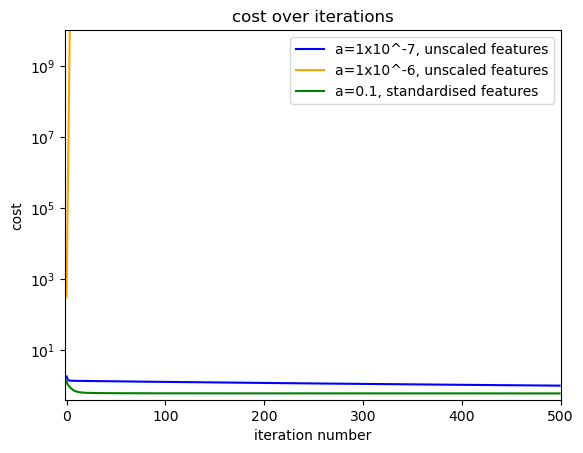

In [4]:
# unscaled
Xb = add_bias(X_tr)
theta, hist = gradient_descent(Xb, y_tr, 10**-7, 500)
plt.plot(np.arange(500), hist, "b", label="a=1x10^-7, unscaled features")

theta, hist = gradient_descent(Xb, y_tr, 10**-6, 500)
plt.plot(np.arange(500), hist, "orange", label="a=1x10^-6, unscaled features")

# standardised
m,s = np.mean(X_tr), np.std(X_tr)
st_X_tr = (X_tr - m)/s
st_Xb = add_bias(st_X_tr)
theta, hist = gradient_descent(st_Xb, y_tr, 0.1, 500)
plt.plot(np.arange(500), hist, "g", label="a=0.1, standardised features")

plt.yscale("log"); plt.ylim(0.4, 10**10); plt.xlim(-2, 500)
plt.xlabel("iteration number"); plt.ylabel("cost"); plt.title("cost over iterations"); plt.legend()
plt.show()

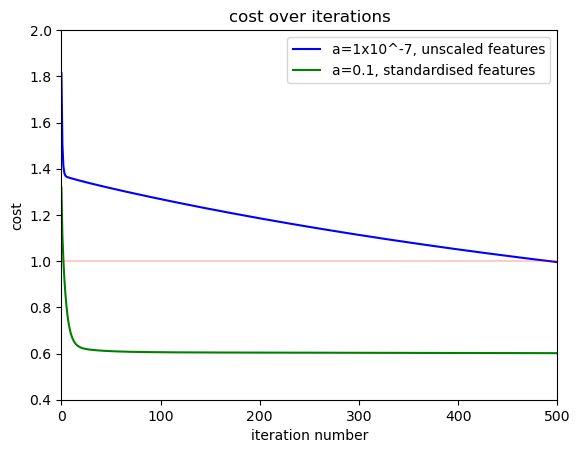

In [5]:
# close up graph for plots that do not significantly deviate :
theta, hist = gradient_descent(Xb, y_tr, 10**-7, 500)
plt.plot(np.arange(500), hist, "b", label="a=1x10^-7, unscaled features")

# standardised
m,s = np.mean(X_tr), np.std(X_tr)
st_X_tr = (X_tr - m)/s
st_Xb = add_bias(st_X_tr)
theta, hist = gradient_descent(st_Xb, y_tr, 0.1, 500)
plt.plot(np.arange(500), hist, "g", label="a=0.1, standardised features")

plt.ylim(0.4, 2); plt.xlim(0, 500)
plt.xlabel("iteration number"); plt.ylabel("cost"); plt.title("cost over iterations"); plt.legend()

# line at cost = 1 to show a=1*10^-7 converging value
plt.plot(np.arange(500), np.ones(500), "r", alpha=0.2)
plt.show()

Here you can see that for unscaled values even at a small alpha value of 10^-6 the cost graph quickly diverges as it tends towards infinity as the limit of the iteration number n tends towards infinity, shown by the orange line quickly leaving the confines of the graph which continues to further as the iteration number increases. When alpha is 10^-7 the line converges instead, showing that you can find theta using unscaled features, but as seen in the blue line of the close up graph it is still very slow to converge compared to scaling the features, only reaching close to its lowest cost at 500 iterations. Additionally, the line appears to slow down and produce a cost close to 1 which is greater than that of the scaled values. In the scaled value graph we use a much greater alpha value of 0.1 and still produce a graph which quickly reduces to a cost around 0.6, within 20 iterations, showing how it is far more suitable as it is not only better, providing a lower cost, but also faster at reaching that value.

## 2. The normal equation (≈15 min)
**TODO 2.1** Solve for $\boldsymbol\theta$ directly with the normal equation. Use
`np.linalg.solve(Xb.T @ Xb, Xb.T @ y)` rather than explicitly inverting (it is faster and numerically
more stable). Compare, in a table, the coefficients from gradient descent, the normal equation and
`LinearRegression`, and the test RMSE of each. Time each method.

In [6]:
# Normal equation method
theta_NM = np.linalg.solve(Xb.T @ Xb, Xb.T @ y_tr)

y_p_NM = add_bias(X_te) @ theta_NM
rmse_NM = np.sqrt(np.mean((y_p_NM-y_te)**2))

# Scikit-learn method
model = LinearRegression()
model.fit(add_bias(X_tr), y_tr)

y_p_SC = model.predict(add_bias(X_te))
theta_SC = model.coef_
theta_SC[0] = model.intercept_
rmse_SC = np.sqrt(np.mean((y_p_SC-y_te)**2))

# Creating comparison table
m,s = np.mean(X_tr, axis=0), np.std(X_tr, axis=0)
st_X_tr = (X_tr - m)/s
st_X_te = (X_te - m)/s
theta, hist = gradient_descent(add_bias(st_X_tr), y_tr)

y_p_GD = add_bias(st_X_te) @ theta
rmse_GD = np.sqrt(np.mean((y_p_GD-y_te)**2))
theta_GD = np.empty_like(theta)
theta_GD[1:] = (theta[1:])/s
theta_GD[0] = theta[0] - np.sum((m/s)*theta[1:])

pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)
compTable = pd.DataFrame(np.array([
    [np.array2string(theta_GD, separator=', ').replace("\n", ""), f"{rmse_GD:.5f}"],
    [np.array2string(theta_NM, separator=', ').replace("\n", ""), f"{rmse_NM:.5f}"],
    [np.array2string(theta_SC, separator=', ').replace("\n", ""), f"{rmse_SC:.5f}"]
    ]), columns=np.array(["Coefficients (theta)", "test RMSE"]), index=np.array(["Multivariate Gradient Descent", "Normal equation", "Linear Regression (sciki-learn)"]))
display(compTable)

,Coefficients (theta),test RMSE
Multivariate Gradient Descent,"[-3.60306374e+01, -4.28595183e-01, -4.24385247e-01, 1.16821852e-02, -7.69646249e-05, 1.02608769e-03, -3.68906000e-04, 5.31440207e-04, 4.00472013e-01]",0.69270
Normal equation,"[-3.63411816e+01, -4.31984707e-01, -4.27153269e-01, 1.16938962e-02, -8.05197604e-05, 1.15106790e-03, -3.60784708e-04, 3.91190939e-04, 4.01558281e-01]",0.69288
Linear Regression (sciki-learn),"[-3.63411816e+01, -4.31984707e-01, -4.27153269e-01, 1.16938962e-02, -8.05197604e-05, 1.15106790e-03, -3.60784708e-04, 3.91190939e-04, 4.01558281e-01]",0.69288


**TODO 2.2** The normal equation needs no learning rate and no iterations, so why ever use gradient
descent? Think about the cost of computing $(X^\top X)^{-1}$ when $n$ is very large, and about
what happens if two features are perfectly correlated.

*Write your answer here.*

gradient decent less accruate => gradient decent sometimes restricted by learning rate, wether the model is scaled well ect ... 

## 3. Polynomial regression (≈25 min)
Polynomial regression is *still linear regression*: we create new features $x, x^2, \dots, x^d$
and fit a linear model in those features.

The dataset below gives the salary for each of the 9 job levels in a company.

**TODO 3.1** Write `poly_features(x, degree)` that returns the matrix $[x, x^2, \dots, x^d]$
(without the bias column). Fit models of degree 1, 2, 3 and 4 using your normal-equation solver
(scale the features first!) and plot all four fitted curves over the data.

            Position  Level  Salary
0  Junior Consultant      1   32000
1  Senior Consultant      2   43000
2            Manager      3   47000
3    Country Manager      4   66000
4     Region Manager      5  120000
5            Partner      6  210000
6     Senior Partner      7  320000
7            C-level      8  500000
8                CEO      9  900000


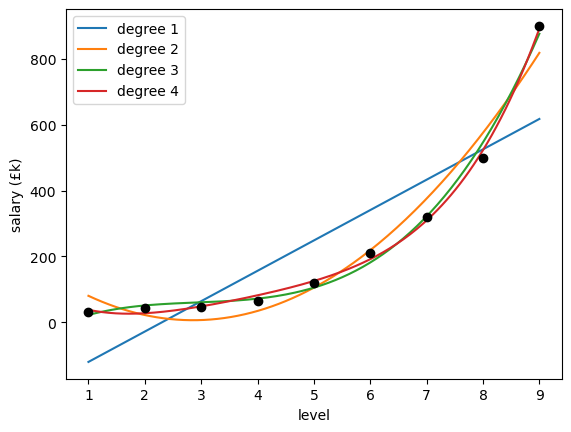

In [7]:
salary = pd.read_csv("https://raw.githubusercontent.com/lshi/ml/main/data/position_salary.csv")
print(salary)
lv = salary["Level"].to_numpy(dtype=float)
sal = salary["Salary"].to_numpy(dtype=float) / 1000   # in £k

def poly_features(x, degree):
    x = np.asarray(x, dtype=float)
    if degree==0:
        return np.empty((len(x),0))
    return np.column_stack([
        x**power
        for power in range(1, degree+1)
    ])

def fit_poly(x, y, degree):
    """Return a function that predicts y for new x, using a degree-d polynomial fitted by the normal equation."""
    Phi = poly_features(x, degree)
    m, s = Phi.mean(0), Phi.std(0)
    Z = (Phi - m)/s if degree>0 else Phi
    theta = np.linalg.solve(add_bias(Z).T @ add_bias(Z), add_bias(Z).T @ y)
    def predict(x_new):
        Phi_new = poly_features(x_new, degree)
        return add_bias((Phi_new-m)/s if degree>0 else Phi_new)@theta
    return predict


xs = np.linspace(1, 9, 200)
plt.scatter(lv, sal, c="k", zorder=3)
for d in [1, 2, 3, 4]:
    predict = fit_poly(lv, sal, d)
    plt.plot(xs, predict(xs), label=f"degree {d}")
plt.xlabel("level"); plt.ylabel("salary (£k)"); plt.legend(); plt.show()

**TODO 3.2** Check your degree-4 model against scikit-learn using
`make_pipeline(PolynomialFeatures(4, include_bias=False), StandardScaler(), LinearRegression())`.
What salary does each predict for level 6.5?

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

model = make_pipeline(PolynomialFeatures(4, include_bias=False), StandardScaler(), LinearRegression())
model.fit(lv.reshape(-1,1), sal)
prediciton_SK = model.predict([[6.5]])
predict = fit_poly(lv, sal, 4)
prediciton_PR = predict([[6.5]])

print(f"For level 6.5, My model predicts salary £{prediciton_PR[0]:.2f} while sklearn predicts £{prediciton_SK[0]:.2f}")
print("These are the same values so model verified.")


For level 6.5, My model predicts salary £241.80 while sklearn predicts £241.80
These are the same values so model verified.


## 4. Underfitting, overfitting, bias and variance (≈30 min)
Nine points are too few to study generalisation, so we simulate data from a known curve,
$y = \sin(2\pi x) + \varepsilon$, with 30 training points and a large validation set.

**TODO 4.1** For degrees $d = 0,1,\dots,15$, fit a polynomial on the training set and record the
training and validation RMSE. Plot both against $d$ (log-scale y-axis). Mark the regions of
**underfitting (high bias)** and **overfitting (high variance)**. Which degree would you choose?

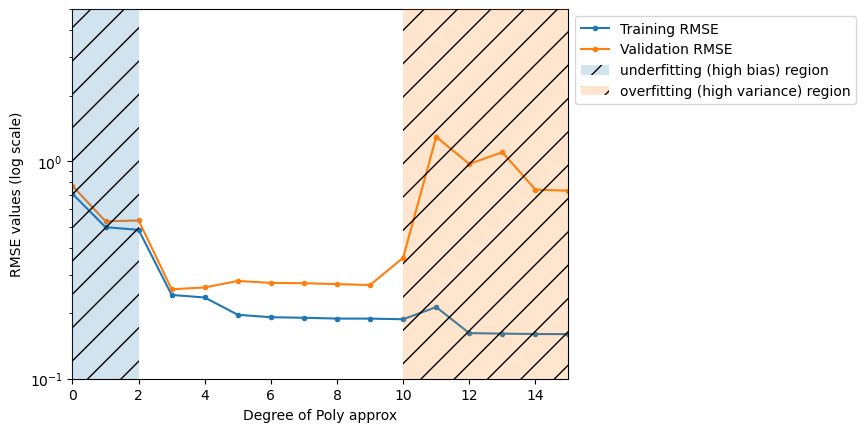

In [ ]:
def make_sine(n, noise=0.25, seed=None):
    g = np.random.default_rng(seed)
    x = g.uniform(0, 1, n)
    return x, np.sin(2 * np.pi * x) + g.normal(0, noise, n)

x_tr, y_tr = make_sine(30, seed=1)
x_va, y_va = make_sine(1000, seed=2)
degrees = range(0, 16)

def rmse_of(f, x, y):
    return np.sqrt(np.mean((f(x) - y) ** 2))

rmse_va = []
rmse_tr = []
for d in degrees:
    predict = fit_poly(x_tr, y_tr, d)
    rmse_tr.append(rmse_of(predict, x_tr, y_tr))
    rmse_va.append(rmse_of(predict, x_va, y_va))
plt.plot(degrees, rmse_tr, label="Training RMSE", marker='.', linestyle='-')
plt.plot(degrees, rmse_va, label="Validation RMSE", marker='.', linestyle='-')

plt.fill_between(range(0,3), np.full(3, 0), np.full(3, 10), zorder=10, hatch="/", alpha=0.2, label="underfitting (high bias) region")
plt.fill_between(range(10,16), np.full(6, 0), np.full(6, 10), zorder=10, hatch="/", alpha=0.2, label="overfitting (high variance) region")

plt.xlabel("Degree of Poly approx"); plt.ylabel("RMSE values (log scale)"); plt.legend(bbox_to_anchor=(1, 1)); plt.yscale("log"); plt.ylim(0.1, 5); plt.xlim(0, 15); plt.show()

I would choose degree 3 as both the training and validation RMSE are low, but specifically the validation rmse is lowest.

**TODO 4.2** Plot the fitted curves for $d = 1$, your best $d$, and $d = 15$ over the training data
(limit the y-axis to $[-2, 2]$). Describe each in terms of bias and variance.

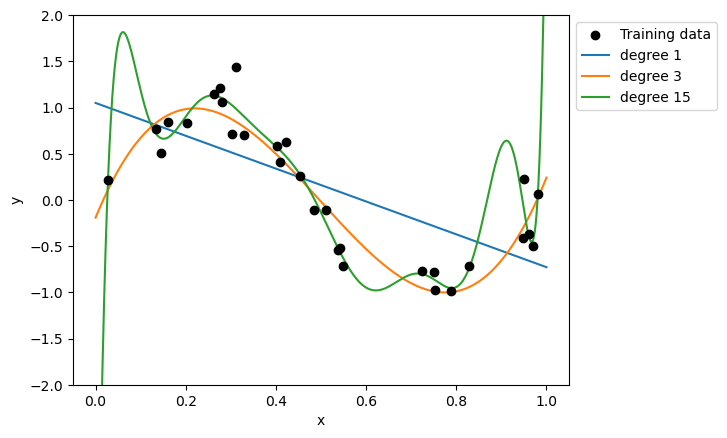

In [36]:
xs = np.linspace(0, 1, 1000)
plt.scatter(x_tr, y_tr, c="k", zorder=3, label="Training data")
for d in [1, 3, 15]:
    predict = fit_poly(x_tr, y_tr, d)
    plt.plot(xs, predict(xs), label=f"degree {d}")
plt.xlabel("x"); plt.ylabel("y"); plt.ylim(-2, 2); plt.legend(bbox_to_anchor=(1, 1)); plt.show()

The degree 1 curve has the highest bias, while having low variance, as it consistently misses the training data values, showing a systematic error in our restricted assumption of degree = 1. The degree 15 curve has low bias but high variance as you can see it is very sensitive to our training data as it hits most points accurately but the overall curve is specific to the data given so would dramatically change given different data points, suggesting its not actually representative of the actual curve. The degree 3 curve has the best balance between not overfitting causing high variance and not underfitting causing high bias. It is the best middle ground ensuring each of the variance and bias are as low as they can be while striking a balance between the 2.

**TODO 4.3 — Variance, directly.** Draw 20 *different* training sets of 30 points (different seeds),
fit a degree-1, a degree-4 and a degree-15 polynomial to each, and plot all 20 curves for each degree
on its own axes. How does this picture explain the words *bias* and *variance*?

/var/folders/_d/gvlqcfrj5fd6gk2rxxct4j1r0000gn/T/ipykernel_37545/510182255.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.xlabel("x"); plt.ylabel("y"); plt.ylim(-2, 2); plt.legend(bbox_to_anchor=(1, 1)); plt.show()


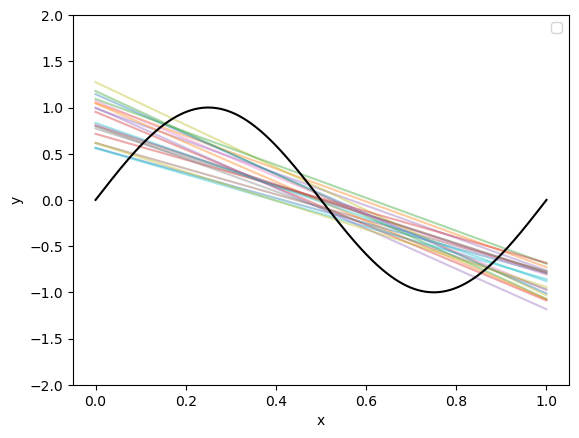

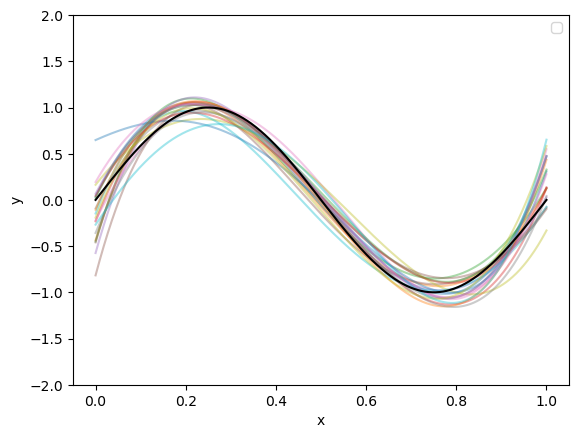

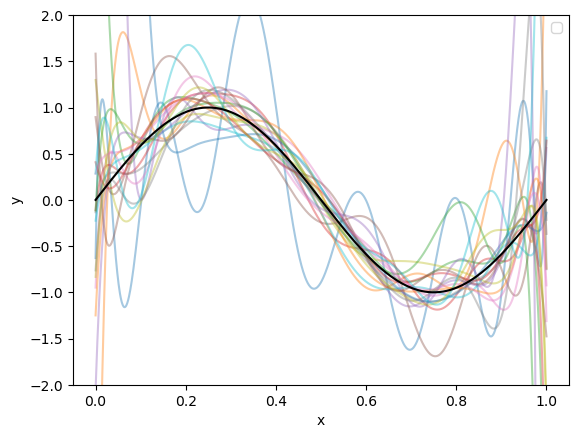

In [41]:
for d in [1, 4, 15]:
    for i in range(20):
        x_tr, y_tr = make_sine(30, seed=i)
        xs = np.linspace(0, 1, 1000)
        predict = fit_poly(x_tr, y_tr, d)
        plt.plot(xs, predict(xs), alpha=0.4)
    plt.plot(xs, np.sin(2*np.pi*xs), color="k")
    plt.xlabel("x"); plt.ylabel("y"); plt.ylim(-2, 2); plt.legend(bbox_to_anchor=(1, 1)); plt.show()



The first plot shows high bias as every curve plotted is similar but cannot accurately represent the actual sine curve. The second plot shows balance as there is still differences in the line but overall is accurate to the actual sine curve and doesnt vary much in every plot. The third plot shows high variance as overall the sine curve is roughly followed but the plot is very messy due to the overfitting in each respective line causing every plot to be different and represent the same line differently.

## 5. Extension: learning curves
Fix the degree (try 1, 4 and 15) and vary the training-set size from 10 to 500. Plot training and
validation RMSE against training-set size. Which model benefits from more data, and which does not?
(`sklearn.model_selection.learning_curve` does this for you — but try it by hand first.)

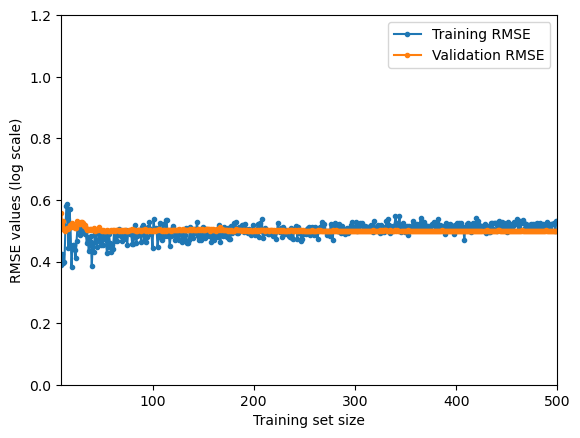

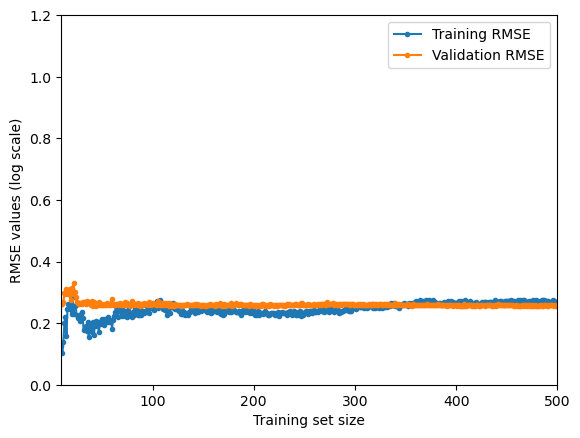

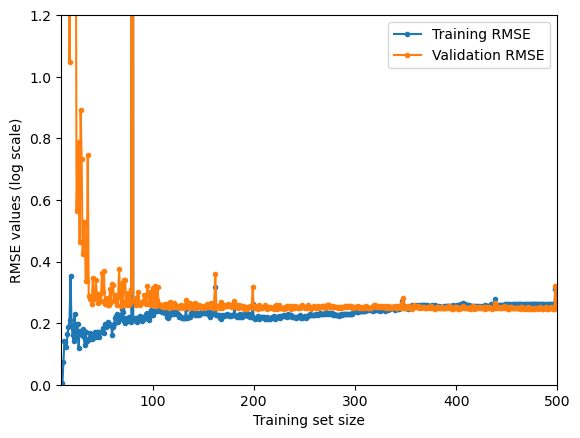

In [ ]:
x_tr, y_tr = make_sine(30, seed=1)
x_va, y_va = make_sine(1000, seed=2)
degrees = [1, 4, 15]

xs = range(10, 501)
for d in degrees:
    rmse_tr = []
    rmse_va = []
    for i in xs:
        x_tr, y_tr = make_sine(i, seed=1)
        predict = fit_poly(x_tr, y_tr, d)
        rmse_tr.append(rmse_of(predict, x_tr, y_tr))
        rmse_va.append(rmse_of(predict, x_va, y_va))
    plt.plot(xs, rmse_tr, label="Training RMSE", marker='.', linestyle='-')
    plt.plot(xs, rmse_va, label="Validation RMSE", marker='.', linestyle='-')
    plt.xlabel("Training set size"); plt.ylabel("RMSE values"); plt.legend(bbox_to_anchor=(1, 1)); plt.ylim(0, 1.2); plt.xlim(10, 500); plt.show()

In the first plot the bias plateus 

## Lab report checklist (Practical 4)
1. The cost-curve figure comparing unscaled and standardised features, with your explanation.
2. The coefficient/RMSE table comparing gradient descent, normal equation and scikit-learn; one sentence on when you would prefer each solver.
3. The training-vs-validation error plot against polynomial degree, with the underfitting and overfitting regions identified and your chosen degree.
4. Your interpretation of bias and variance, referring to your figure from 4.3.